# Лабораторная работа № 3. Linear Soft-Margin SVM

Цель — самостоятельно реализовать линейный SVM, подобрать настройки по validation и сравнить с логистической регрессией из ЛР1 на общем разбиении. Все вычисления модели выполняются тензорами PyTorch, основные градиенты, метрики, разбиение и масштабирование реализованы вручную. Случайные операции: seed 6752.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from models.svm import LinearSVM
from models.logistic_regression import LogisticRegression
from split import stratified_split_indices
from preprocessing import StandardScaler
from evaluation import classification_metrics, roc_curve, precision_recall_curve, auc

SEED = 6752
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 10, 'axes.grid': True})
FIGURES = Path('docs/figures')
FIGURES.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=160, bbox_inches='tight')
    plt.show()

## 1. Загрузка и исследование данных

Одна строка — объект: изображение банкноты, описанное четырьмя числовыми характеристиками. `class` — бинарная целевая переменная. CSV содержит имена столбцов; приложенный UCI TXT содержит те же строки без заголовка. Сверим файлы и удалим точные повторы **до разбиения**, чтобы одинаковые наблюдения не попадали в разные выборки. Это решение аналогично ЛР2.

In [2]:
csv_data = pd.read_csv('data/BankNote_Authentication.csv')
uci_data = pd.read_csv('data/data_banknote_authentication.txt', header=None, names=csv_data.columns)
assert csv_data.equals(uci_data), 'Содержимое двух файлов различается'
print('Файлы совпадают построчно:', len(csv_data), 'строк')
print('Пропуски по столбцам:')
display(csv_data.isna().sum().to_frame('Пропуски'))
display(csv_data.head())
print('Количество объектов по классам до удаления повторов:')
display(csv_data['class'].value_counts().sort_index().to_frame('Число объектов'))
unique_data = csv_data.drop_duplicates().reset_index(drop=True)
print(f'Удалено полных дубликатов: {len(csv_data) - len(unique_data)}; осталось: {len(unique_data)}')
features = ['variance', 'skewness', 'curtosis', 'entropy']
assert unique_data.groupby(features)['class'].nunique().max() == 1
X = unique_data[features].to_numpy(dtype=float)
y = unique_data['class'].to_numpy(dtype=int)
y_svm = 2 * y - 1
display(unique_data.groupby('class').size().to_frame('Объекты после очистки'))

Файлы совпадают построчно: 1372 строк
Пропуски по столбцам:


,Пропуски
variance,0
skewness,0
curtosis,0
entropy,0
class,0


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Количество объектов по классам до удаления повторов:


,Число объектов
class,
0,762
1,610


Удалено полных дубликатов: 24; осталось: 1348


,Объекты после очистки
class,
0,738
1,610


## 2. Разбиение и масштабирование

Стратификация отдельно перемешивает индексы классов. Среднее и стандартное отклонение вычисляются **только на train**; validation и test преобразуются с этими же параметрами. Доля train/validation/test — 60/20/20. Для SVM классы 0 и 1 кодируются как −1 и +1.

In [3]:
idx_train, idx_val, idx_test = stratified_split_indices(y, train_size=0.6, val_size=0.2, seed=SEED)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))
X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
ym_train, ym_val = y_svm[idx_train], y_svm[idx_val]
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)
for name, labels in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{name:10}: n={len(labels)}, класс 0={sum(labels == 0)}, класс 1={sum(labels == 1)}')

train     : n=808, класс 0=442, класс 1=366
validation: n=269, класс 0=147, класс 1=122
test      : n=271, класс 0=149, класс 1=122


## 3. Эксперименты с SVM

Минимизируется $J=\frac{\lambda}{2}\lVert w\rVert^2+\frac{1}{N}\sum_i\max(0,1-y_i(w^Tx_i+b))$. В каждой эпохе объекты перемешиваются и выполняется обновление на каждом батче. $b$ не регуляризуется. Для каждой комбинации $\lambda$ и размера батча выполняется один запуск с фиксированным seed; лучшая эпоха определяется по минимуму **validation hinge loss**. Затем среди всех комбинаций выбирается наименьший validation hinge loss. Test не участвует в выборе. Один и тот же поиск выполняется отдельно с масштабированием и без него.

In [4]:
LAMBDAS = [0.001, 0.01, 0.1, 1.0]
BATCHES = [32, 128, len(X_train)]
MAX_EPOCHS = 1200
LR = 0.01
results = []
models = {}
for scale_name, xt, xv in [('без scaling', X_train, X_val), ('со scaling', X_train_sc, X_val_sc)]:
    for l2 in LAMBDAS:
        for batch in BATCHES:
            model = LinearSVM(learning_rate=LR, epochs=MAX_EPOCHS, batch_size=batch, l2=l2, seed=SEED)
            model.fit(xt, ym_train, validation_data=(xv, ym_val))
            best_epoch = int(np.argmin(model.validation_hinge_history_)) + 1
            results.append({'scaling': scale_name, 'lambda': l2, 'batch_size': batch,
                            'epoch': best_epoch, 'val_hinge': model.validation_hinge_history_[best_epoch - 1]})
            models[(scale_name, l2, batch)] = model
search = pd.DataFrame(results)
best = (search.sort_values(['val_hinge', 'epoch', 'lambda', 'batch_size'])
        .groupby('scaling', sort=False).first())
display(search.sort_values(['scaling', 'val_hinge']).reset_index(drop=True))
print('Лучшие конфигурации по validation hinge loss:')
display(best)

,scaling,lambda,batch_size,epoch,val_hinge
0,без scaling,0.001,32,1198,0.017851
1,без scaling,0.010,32,717,0.019387
2,без scaling,0.001,128,1196,0.019559
3,без scaling,0.010,128,1174,0.020127
4,без scaling,0.001,808,1200,0.031169
5,без scaling,0.010,808,1200,0.032111
6,без scaling,0.100,32,1080,0.040962
7,без scaling,0.100,128,655,0.041743
8,без scaling,0.100,808,1200,0.047922
9,без scaling,1.000,32,790,0.095022


Лучшие конфигурации по validation hinge loss:


,lambda,batch_size,epoch,val_hinge
scaling,,,,
без scaling,0.001,32,1198,0.017851
со scaling,0.001,32,1199,0.026015


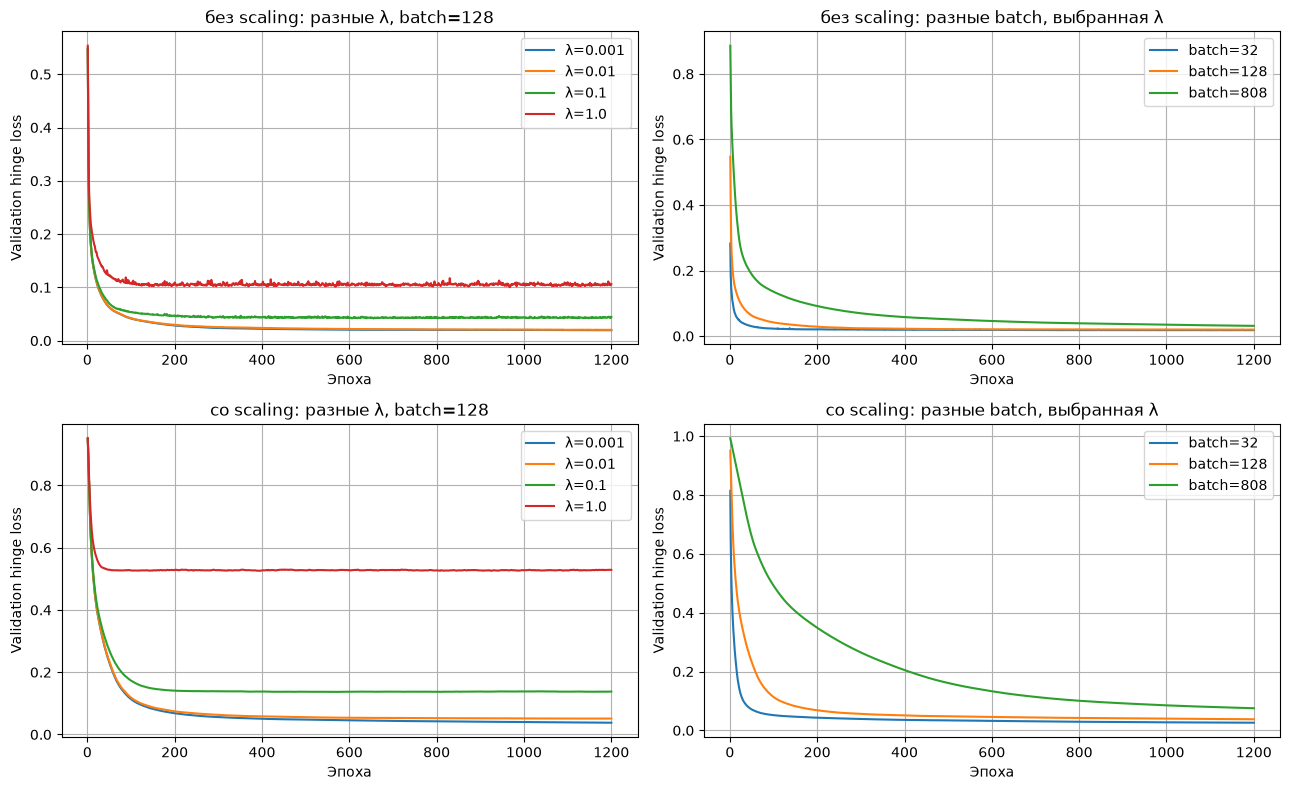

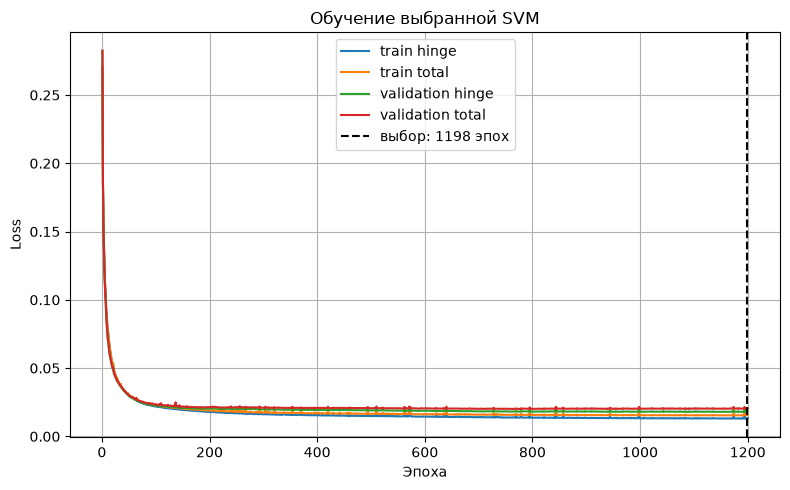

In [5]:
# Кривые нескольких запусков для обоих вариантов масштаба.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, scale_name in enumerate(['без scaling', 'со scaling']):
    for l2 in LAMBDAS:
        m = models[(scale_name, l2, 128)]
        axes[row,0].plot(np.arange(1, MAX_EPOCHS + 1), m.validation_hinge_history_, label=f'λ={l2}')
    for batch in BATCHES:
        m = models[(scale_name, float(best.loc[scale_name, 'lambda']), batch)]
        axes[row,1].plot(np.arange(1, MAX_EPOCHS + 1), m.validation_hinge_history_, label=f'batch={batch}')
    axes[row,0].set_title(f'{scale_name}: разные λ, batch=128')
    axes[row,1].set_title(f'{scale_name}: разные batch, выбранная λ')
for ax in axes.flat:
    ax.set(xlabel='Эпоха', ylabel='Validation hinge loss')
    ax.legend()
savefig('validation_epochs.png')

selected_scaling = best['val_hinge'].idxmin()
selected = best.loc[selected_scaling]
selected_model = models[(selected_scaling, float(selected['lambda']), int(selected['batch_size']))]
epoch_axis = np.arange(1, MAX_EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_axis, selected_model.hinge_history_, label='train hinge')
ax.plot(epoch_axis, selected_model.history_, label='train total')
ax.plot(epoch_axis, selected_model.validation_hinge_history_, label='validation hinge')
ax.plot(epoch_axis, selected_model.validation_history_, label='validation total')
ax.axvline(int(selected['epoch']), color='black', ls='--', label=f"выбор: {int(selected['epoch'])} эпох")
ax.set(xlabel='Эпоха', ylabel='Loss', title='Обучение выбранной SVM')
ax.legend(); savefig('learning_curves.png')

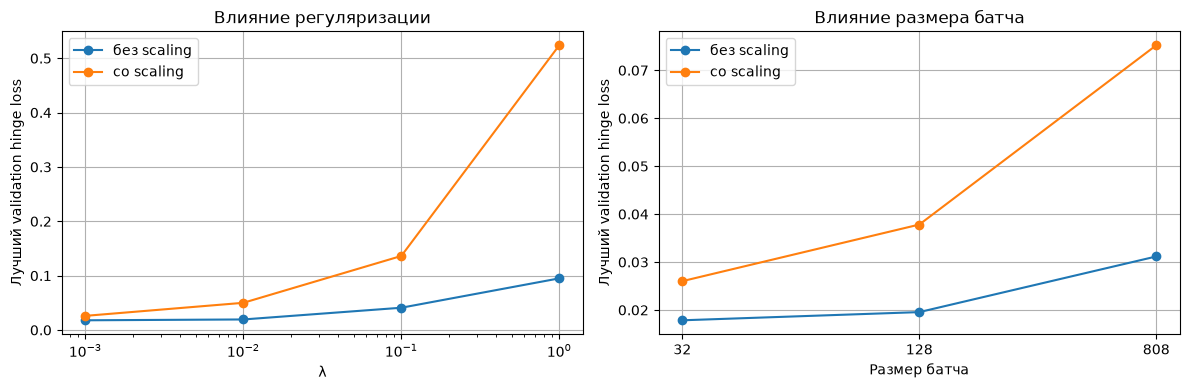

без scaling выбрано эпох: 1198 из 1200 | лучшая validation hinge: 0.01785 | минимум на границе бюджета: False


со scaling выбрано эпох: 1199 из 1200 | лучшая validation hinge: 0.02601 | минимум на границе бюджета: False


,Accuracy,Precision,Recall,F1
без scaling,0.996283,0.991870,1.0,0.995918
со scaling,0.992565,0.983871,1.0,0.991870


Итоговый SVM по validation: SVM без scaling


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scale_name, group in search.groupby('scaling'):
    by_lambda = group.groupby('lambda')['val_hinge'].min()
    by_batch = group.groupby('batch_size')['val_hinge'].min()
    axes[0].plot(by_lambda.index, by_lambda.values, marker='o', label=scale_name)
    axes[1].plot(range(len(by_batch)), by_batch.values, marker='o', label=scale_name)
axes[0].set(xscale='log', xlabel='λ', ylabel='Лучший validation hinge loss', title='Влияние регуляризации')
axes[1].set(xticks=range(len(BATCHES)), xticklabels=[str(b) for b in BATCHES],
            xlabel='Размер батча', ylabel='Лучший validation hinge loss', title='Влияние размера батча')
for ax in axes: ax.legend()
savefig('hyperparameters.png')

svms = {}
for scale_name, xt in [('без scaling', X_train), ('со scaling', X_train_sc)]:
    row = best.loc[scale_name]
    m = LinearSVM(learning_rate=LR, epochs=int(row['epoch']), batch_size=int(row['batch_size']),
                  l2=float(row['lambda']), seed=SEED)
    m.fit(xt, ym_train)
    svms[scale_name] = m
    print(scale_name, 'выбрано эпох:', int(row['epoch']), 'из', MAX_EPOCHS,
          '| лучшая validation hinge:', f"{row['val_hinge']:.5f}",
          '| минимум на границе бюджета:', int(row['epoch']) == MAX_EPOCHS)
validation_results = {}
for name, values in [('без scaling', X_val), ('со scaling', X_val_sc)]:
    val_pred = (svms[name].decision_function(values) >= 0).astype(int)
    validation_results[name] = classification_metrics(y_val, val_pred)
display(pd.DataFrame(validation_results).T[['Accuracy', 'Precision', 'Recall', 'F1']])
# Масштабирование выбираем тем же критерием, до обращения к test.
chosen_scaling = best['val_hinge'].idxmin()
chosen_name = 'SVM со scaling' if chosen_scaling == 'со scaling' else 'SVM без scaling'
print('Итоговый SVM по validation:', chosen_name)

Верхняя граница в 1200 эпох — бюджет эксперимента, а не доказательство оптимального числа эпох за его пределами. Графики нескольких запусков показывают, достигается ли минимум внутри проверенного интервала. После выбора модель заново обучается тем же seed на train на выбранное число эпох. Параметры на validation/test не обучаются.

## 4. Сравнение с логистической регрессией ЛР1

Используем ту же stratified выборку и те же train-only параметры scaling. Для логистической регрессии отдельно выбираем скорость обучения и число эпох по наименьшей validation BCE; вероятности получаем из `predict_proba`. Графики нескольких запусков показывают изменение ошибки на обучении, а таблица — ошибку на validation.

,learning_rate,epochs,validation_bce
0,0.05,250,0.259278
1,0.05,1000,0.114914
2,0.05,3000,0.060568
3,0.05,6000,0.043234
4,0.05,12000,0.032170
5,0.50,250,0.066615
6,0.50,1000,0.034641
7,0.50,3000,0.022824
8,0.50,6000,0.018603
9,0.50,12000,0.016065


Выбрано LR: learning_rate=1.0, эпох=12000; минимум на границе бюджета: True


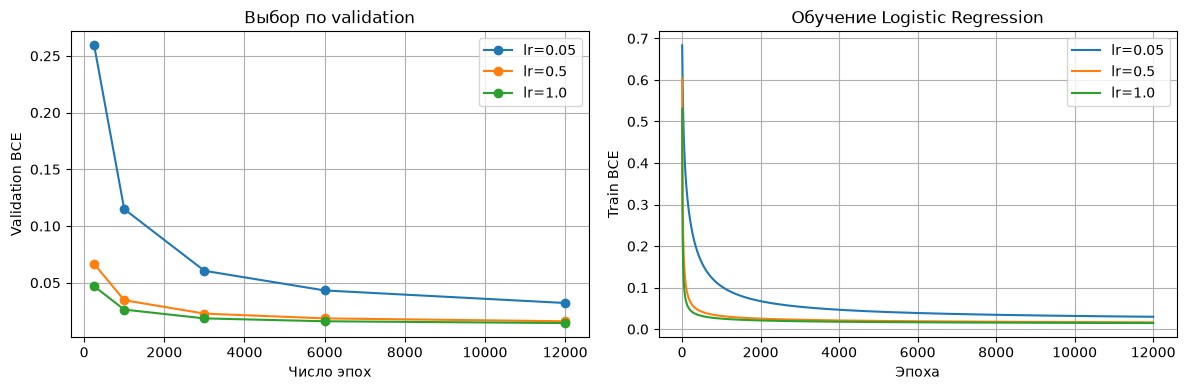

In [7]:
lr_candidates = {}
lr_rows = []
for rate in [0.05, 0.5, 1.0]:
    for epochs in [250, 1000, 3000, 6000, 12000]:
        m = LogisticRegression(learning_rate=rate, epochs=epochs)
        m.fit(X_train_sc, y_train)
        prob = np.clip(m.predict_proba(X_val_sc), 1e-15, 1 - 1e-15)
        val_bce = float(-np.mean(y_val * np.log(prob) + (1-y_val)*np.log(1-prob)))
        lr_rows.append({'learning_rate': rate, 'epochs': epochs, 'validation_bce': val_bce})
        lr_candidates[(rate, epochs)] = m
lr_search = pd.DataFrame(lr_rows)
display(lr_search)
lr_choice = lr_search.loc[lr_search.validation_bce.idxmin()]
lr_epochs, lr_rate = int(lr_choice['epochs']), float(lr_choice['learning_rate'])
lr_model = lr_candidates[(lr_rate, lr_epochs)]
print(f'Выбрано LR: learning_rate={lr_rate}, эпох={lr_epochs}; минимум на границе бюджета: {lr_epochs == 12000}')
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for rate, group in lr_search.groupby('learning_rate'):
    axes[0].plot(group['epochs'], group['validation_bce'], marker='o', label=f'lr={rate}')
    m = lr_candidates[(rate, 12000)]
    axes[1].plot(np.arange(1, 12001), m.history_, label=f'lr={rate}')
axes[0].set(xlabel='Число эпох', ylabel='Validation BCE', title='Выбор по validation')
axes[1].set(xlabel='Эпоха', ylabel='Train BCE', title='Обучение Logistic Regression')
for ax in axes: ax.legend()
savefig('logistic_learning.png')

## 5. Итоговая оценка на test

Все настройки уже выбраны на validation. Порог для SVM — score 0, для Logistic Regression — вероятность 0,5. Кривые ROC и Precision–Recall строятся по непрерывным оценкам; площадь вычисляется методом трапеций, поэтому PR-AUC здесь не тождественна average precision. Начальная точка PR принимается как (recall=0, precision=1).

In [8]:
def test_summary(model, values, is_svm):
    score = model.decision_function(values) if is_svm else model.predict_proba(values)
    predicted = (score >= (0 if is_svm else 0.5)).astype(int)
    metrics = classification_metrics(y_test, predicted)
    fpr, tpr, _ = roc_curve(y_test, score)
    recall, precision, _ = precision_recall_curve(y_test, score)
    metrics.update({'ROC-AUC': auc(fpr, tpr), 'PR-AUC': auc(recall, precision)})
    return metrics, score, predicted, (fpr, tpr), (recall, precision)

outputs = {
    'SVM без scaling': test_summary(svms['без scaling'], X_test, True),
    'SVM со scaling': test_summary(svms['со scaling'], X_test_sc, True),
    'Logistic Regression': test_summary(lr_model, X_test_sc, False),
}
metrics_table = pd.DataFrame({name: value[0] for name, value in outputs.items()}).T[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']]
print('Итоговые метрики test (после выбора настроек):')
display(metrics_table)

Итоговые метрики test (после выбора настроек):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
SVM без scaling,0.99631,1.000000,0.991803,0.995885,1.000000,1.000000
SVM со scaling,0.99262,0.991803,0.991803,0.991803,0.999945,0.999933
Logistic Regression,0.99631,1.000000,0.991803,0.995885,0.999945,0.999933


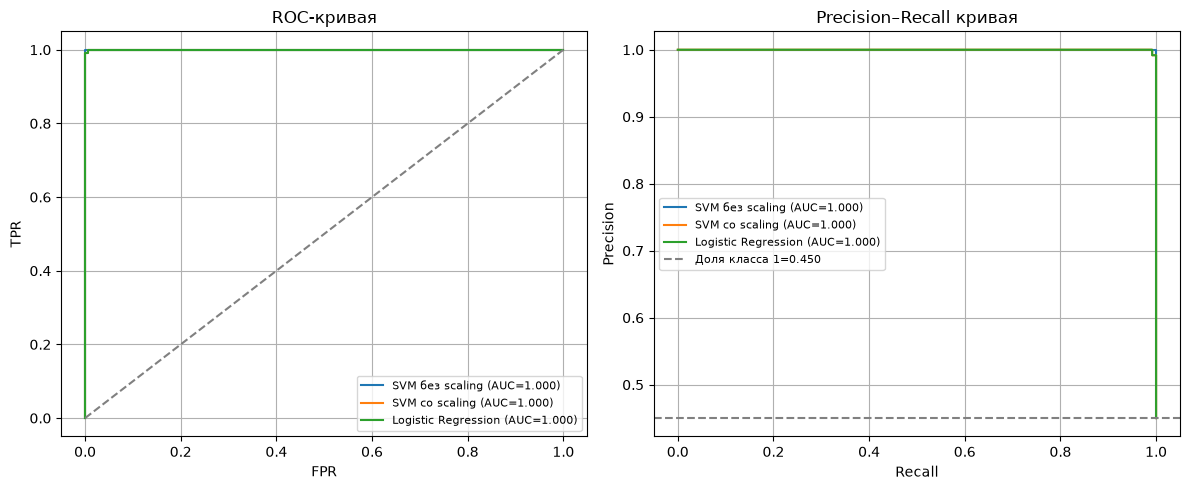

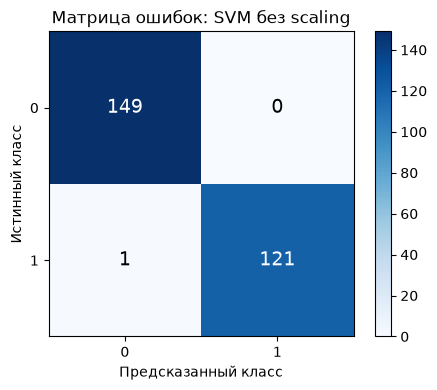

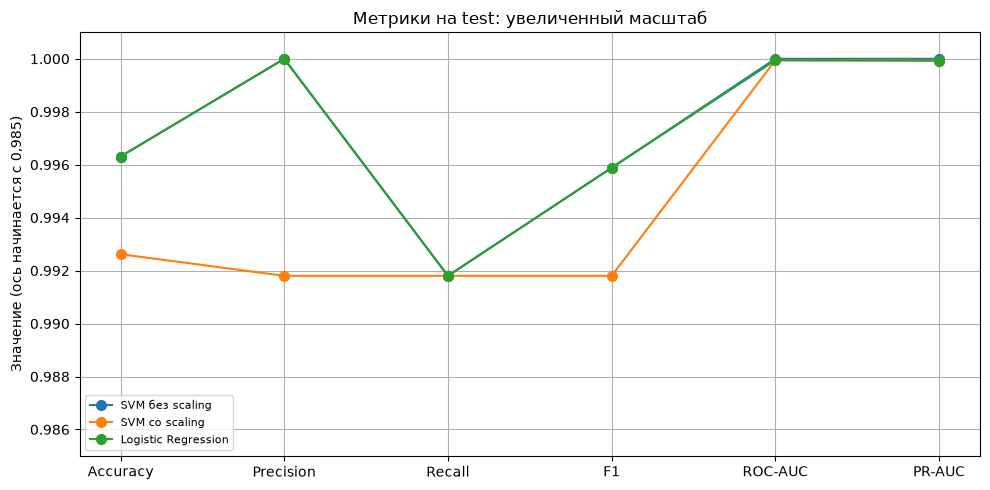

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (metrics, scores, pred, roc, pr) in outputs.items():
    axes[0].plot(*roc, label=f"{name} (AUC={metrics['ROC-AUC']:.3f})")
    axes[1].plot(*pr, label=f"{name} (AUC={metrics['PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC-кривая')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label=f'Доля класса 1={y_test.mean():.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall кривая')
for ax in axes: ax.legend(fontsize=8)
savefig('roc_pr.png')

pred = outputs[chosen_name][2]
cm = np.array([[np.sum((y_test == actual) & (pred == predicted)) for predicted in [0, 1]] for actual in [0, 1]])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues'); ax.grid(False); plt.colorbar(im, ax=ax)
for i in range(2):
    for j in range(2): ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14, color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set(xticks=[0,1], yticks=[0,1], xlabel='Предсказанный класс', ylabel='Истинный класс', title=f'Матрица ошибок: {chosen_name}')
savefig('confusion_matrix.png')
fig, ax = plt.subplots(figsize=(10, 5))
for name, row in metrics_table.iterrows():
    ax.plot(metrics_table.columns, row.values, marker='o', markersize=7, label=name)
ax.set(ylim=(0.985, 1.001), ylabel='Значение (ось начинается с 0,985)', title='Метрики на test: увеличенный масштаб')
ax.legend(fontsize=8, loc='lower left')
savefig('model_comparison.png')

## 6. Геометрия SVM на двух признаках

Здесь обучается отдельная модель только по `variance` и `skewness`. Сплошная линия — score=0, пунктирные — score=−1 и +1. Кольцами выделены объекты train с $y_i f(x_i)\leq1$. Это иллюстрация геометрии, а не модель для итоговых метрик.

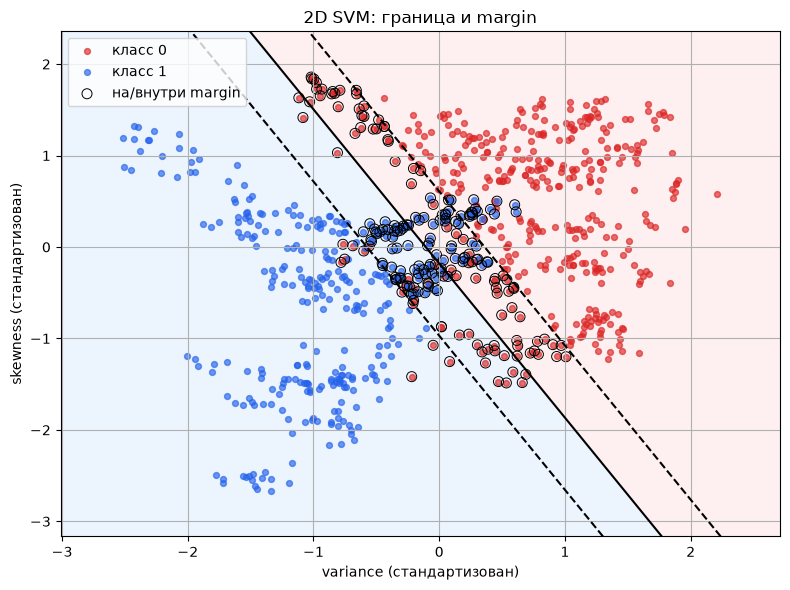

Train-объектов на или внутри margin в 2D: 209 из 808


In [10]:
two_scaler = StandardScaler().fit(X_train[:, :2])
X2_train = two_scaler.transform(X_train[:, :2])
two_model = LinearSVM(learning_rate=LR, epochs=int(selected['epoch']), batch_size=int(selected['batch_size']),
                      l2=float(selected['lambda']), seed=SEED).fit(X2_train, ym_train)
a = np.linspace(X2_train[:,0].min()-0.5, X2_train[:,0].max()+0.5, 200)
b = np.linspace(X2_train[:,1].min()-0.5, X2_train[:,1].max()+0.5, 200)
xx, yy = np.meshgrid(a,b)
zz = two_model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
margin_points = ym_train * two_model.decision_function(X2_train) <= 1 + 1e-10
fig, ax = plt.subplots(figsize=(8,6))
ax.contourf(xx, yy, zz, levels=[zz.min()-1, 0, zz.max()+1], colors=['#fee2e2','#dbeafe'], alpha=0.5)
ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors=['black']*3, linestyles=['--','-','--'])
for cls, color in [(0, '#dc2626'), (1, '#2563eb')]:
    mask = y_train == cls
    ax.scatter(X2_train[mask, 0], X2_train[mask, 1], s=18, c=color, alpha=0.65, label=f'класс {cls}')
ax.scatter(X2_train[margin_points,0], X2_train[margin_points,1], s=52, facecolors='none', edgecolors='black', linewidths=0.7, label='на/внутри margin')
ax.set(xlabel='variance (стандартизован)', ylabel='skewness (стандартизован)', title='2D SVM: граница и margin')
ax.legend(); savefig('svm_2d.png')
print('Train-объектов на или внутри margin в 2D:', int(margin_points.sum()), 'из', len(ym_train))

## 7. Выводы

Выбор регуляризации, батча и эпох основывался только на validation; test использовался для итогового сравнения. ROC-AUC оценивает ранжирование положительных объектов относительно отрицательных; PR-AUC показывает соотношение precision и recall при разных порогах и зависит от доли положительного класса. Для признаков переобучения полезно сравнить train и validation loss: один только test или разница accuracy не доказывает его наличия. Геометрический рисунок использует две координаты, тогда как окончательная оценка — все четыре признака.

In [11]:
summary = {
    'seed': SEED, 'n_original': len(csv_data), 'n_unique': len(unique_data),
    'split_sizes': {'train': len(idx_train), 'validation': len(idx_val), 'test': len(idx_test)},
    'search': search.to_dict(orient='records'), 'validation_metrics_svm': validation_results, 'lr_search': lr_rows,
    'selected_hinge_train': selected_model.hinge_history_[int(selected['epoch']) - 1],
    'selected_val_hinge_checkpoints': {str(e): selected_model.validation_hinge_history_[e - 1] for e in [300, 600, 900, 1200]},
    'lr_selected_epochs': lr_epochs, 'lr_selected_learning_rate': lr_rate, 'chosen_svm': chosen_name, 'metrics': metrics_table.to_dict(orient='index'),
    'confusion_matrix_chosen_svm': cm.tolist(), 'two_dimensional_margin_count': int(margin_points.sum()),
}
Path('docs/results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Численные результаты сохранены в docs/results.json')
for scale_name in ['со scaling','без scaling']:
    r = best.loc[scale_name]
    print(f"{scale_name}: λ={r['lambda']}, batch={int(r['batch_size'])}, эпох={int(r['epoch'])}, validation hinge={r['val_hinge']:.4f}")
print('Модель, масштабирование и LR сравниваются по таблице выше; про влияние scaling судим с учётом метрик и величины выборки.')
print('Итоговый вариант:', chosen_name)
print(f"Для выбранной SVM на эпохе {int(selected['epoch'])}: train hinge={selected_model.hinge_history_[int(selected['epoch'])-1]:.5f}, validation hinge={selected['val_hinge']:.5f}.")
print('Сопоставление train и validation показывает разрыв; по выбранному интервалу одного разбиения нельзя надёжно установить его причину.')
print('Лучшая validation BCE логистической регрессии:', round(float(lr_choice['validation_bce']), 6))
print('Если лучший бюджет находится у края диапазона, его следует понимать как лучший из проверенных, а не как доказанный глобальный оптимум.')

Численные результаты сохранены в docs/results.json
со scaling: λ=0.001, batch=32, эпох=1199, validation hinge=0.0260
без scaling: λ=0.001, batch=32, эпох=1198, validation hinge=0.0179
Модель, масштабирование и LR сравниваются по таблице выше; про влияние scaling судим с учётом метрик и величины выборки.
Итоговый вариант: SVM без scaling
Для выбранной SVM на эпохе 1198: train hinge=0.01312, validation hinge=0.01785.
Сопоставление train и validation показывает разрыв; по выбранному интервалу одного разбиения нельзя надёжно установить его причину.
Лучшая validation BCE логистической регрессии: 0.014484
Если лучший бюджет находится у края диапазона, его следует понимать как лучший из проверенных, а не как доказанный глобальный оптимум.


### Интерпретация полученного запуска

- На validation среди рассмотренных настроек выбран вариант **без scaling**: λ=0,001, batch=32, 1198 эпох. Его hinge loss равен 0,01785; лучший результат со scaling — 0,02601. Сравнение относится к данному разбиению и проверенной сетке; оно не означает, что масштабирование вообще не полезно.
- Минимум выбранного SVM находится у границы 1200 эпох. На 600-й эпохе validation hinge составляет 0,01877, а на выбранной 1198-й — 0,01785. Выбран именно наблюдаемый минимум в проверенном диапазоне; за его пределами оптимум не исследован. Для логистической регрессии лучшая из проверенных конфигураций — learning rate 1 и 12000 эпох; её validation BCE 0,01448 тоже достигнута на границе бюджета.
- На test SVM и логистическая регрессия ошиблись по одному разу: их Accuracy 0,99631 и F1 0,99588. У выбранного SVM ROC-AUC и PR-AUC равны 1 на этой тестовой выборке: порядок score полностью разделил классы, хотя порог 0 дал одну ошибку. Это не доказывает идеального качества на новых данных.
- На выбранной эпохе train hinge составляет 0,01312, validation hinge — 0,01785. На исследованном интервале нет выраженного устойчивого роста validation loss; оба значения невелики, поэтому явных признаков сильного недообучения или переобучения здесь не видно. Одного разбиения недостаточно, чтобы окончательно судить об обобщении.